In [1]:
import pandas as pd

In [2]:
data=pd.read_csv("adult_with_headers (1).csv")
data.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
data.shape

(32561, 15)

In [4]:
data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='object')

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [6]:
data.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [7]:
data["workclass"].value_counts()

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [52]:
for col in data.select_dtypes(include="object").columns:
    print(data[col].value_counts())

In [53]:
for col in data.select_dtypes(include="object").columns:
    print(col)
    print(data[col].value_counts(dropna=False))

In [56]:
import numpy as np
data.replace(r"^\s*\?\s*(?:\.0)?\s*$", np.nan, regex=True, inplace=True)
data

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,income,sex_ Female,sex_ Male,net_capital,work_intensity,capital_gain_log
0,39,7,77516,9,13,4,1,1,4,2174,0,40,39,0,0,1,2174,520,7.684784
1,50,6,83311,9,13,2,4,0,4,0,0,13,39,0,0,1,0,169,0.000000
2,38,4,215646,11,9,0,6,1,4,0,0,40,39,0,0,1,0,360,0.000000
3,53,4,234721,1,7,2,6,0,2,0,0,40,39,0,0,1,0,280,0.000000
4,28,4,338409,9,13,2,10,5,2,0,0,40,5,0,1,0,0,520,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,4,257302,7,12,2,13,5,4,0,0,38,39,0,1,0,0,456,0.000000
32557,40,4,154374,11,9,2,7,0,4,0,0,40,39,1,0,1,0,360,0.000000
32558,58,4,151910,11,9,6,1,4,4,0,0,40,39,0,1,0,0,360,0.000000
32559,22,4,201490,11,9,4,1,3,4,0,0,20,39,0,0,1,0,180,0.000000


### 1) Handle missing values

In [57]:
data.isnull().sum()

age                 0
workclass           0
fnlwgt              0
education           0
education_num       0
marital_status      0
occupation          0
relationship        0
race                0
capital_gain        0
capital_loss        0
hours_per_week      0
native_country      0
income              0
sex_ Female         0
sex_ Male           0
net_capital         0
work_intensity      0
capital_gain_log    0
dtype: int64

In [12]:
col=["workclass","occupation","native_country"]
for i in col:
    data[i]=data[i].fillna(data[i].mode()[0])

In [13]:
data.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [14]:
data.duplicated().sum()

np.int64(24)

In [15]:
data[data.duplicated()].head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
4881,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
5104,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
9171,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
11631,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
13084,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,<=50K


In [16]:
data.drop_duplicates(inplace=True)

In [17]:
data.duplicated().sum()

np.int64(0)

#### Numerical features

#### StandardScaler

In [18]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler

In [19]:
numeric=data.select_dtypes(include="integer")
numeric

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,39,77516,13,2174,0,40
1,50,83311,13,0,0,13
2,38,215646,9,0,0,40
3,53,234721,7,0,0,40
4,28,338409,13,0,0,40
...,...,...,...,...,...,...
32556,27,257302,12,0,0,38
32557,40,154374,9,0,0,40
32558,58,151910,9,0,0,40
32559,22,201490,9,0,0,20


In [20]:
categorical=data.select_dtypes(include="object")
categorical

,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...
32556,Private,Assoc-acdm,Married-civ-spouse,Tech-support,Wife,White,Female,United-States,<=50K
32557,Private,HS-grad,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,United-States,>50K
32558,Private,HS-grad,Widowed,Adm-clerical,Unmarried,White,Female,United-States,<=50K
32559,Private,HS-grad,Never-married,Adm-clerical,Own-child,White,Male,United-States,<=50K


In [21]:
scaler=StandardScaler()
scaled_data=scaler.fit_transform(numeric)
scaled_data

array([[ 0.03038995, -1.06356884,  1.13477712,  0.14829174, -0.21674317,
        -0.03566374],
       [ 0.8369732 , -1.00866848,  1.13477712, -0.14597544, -0.21674317,
        -2.22248299],
       [-0.0429358 ,  0.24503992, -0.42067868, -0.14597544, -0.21674317,
        -0.03566374],
       ...,
       [ 1.42357919, -0.35877886, -0.42067868, -0.14597544, -0.21674317,
        -0.03566374],
       [-1.2161478 ,  0.11092955, -0.42067868, -0.14597544, -0.21674317,
        -1.65552985],
       [ 0.9836247 ,  0.92981187, -0.42067868,  1.88763548, -0.21674317,
        -0.03566374]], shape=(32537, 6))

In [22]:
scaled_df=pd.DataFrame(scaled_data,columns=numeric.columns)
scaled_df.head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,0.030390,-1.063569,1.134777,0.148292,-0.216743,-0.035664
1,0.836973,-1.008668,1.134777,-0.145975,-0.216743,-2.222483
2,-0.042936,0.245040,-0.420679,-0.145975,-0.216743,-0.035664
3,1.056950,0.425752,-1.198407,-0.145975,-0.216743,-0.035664
4,-0.776193,1.408066,1.134777,-0.145975,-0.216743,-0.035664


#### StandardScaler transforms features so they have approximately mean 0 and standard deviation 1. It is generally preferred for algorithms such as Logistic Regression, SVM, KNN and PCA where the scale of features affects model performance.

#### Minmax scalling

In [23]:
minmax=MinMaxScaler()
minmax_data=minmax.fit_transform(numeric)
minmax_data

array([[0.30136986, 0.0443019 , 0.8       , 0.02174022, 0.        ,
        0.39795918],
       [0.45205479, 0.0482376 , 0.8       , 0.        , 0.        ,
        0.12244898],
       [0.28767123, 0.13811345, 0.53333333, 0.        , 0.        ,
        0.39795918],
       ...,
       [0.56164384, 0.09482688, 0.53333333, 0.        , 0.        ,
        0.39795918],
       [0.06849315, 0.12849934, 0.53333333, 0.        , 0.        ,
        0.19387755],
       [0.47945205, 0.18720338, 0.53333333, 0.1502415 , 0.        ,
        0.39795918]], shape=(32537, 6))

In [24]:
minmax_df=pd.DataFrame(minmax_data,columns=numeric.columns)
minmax_df.head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,0.301370,0.044302,0.800000,0.02174,0.0,0.397959
1,0.452055,0.048238,0.800000,0.00000,0.0,0.122449
2,0.287671,0.138113,0.533333,0.00000,0.0,0.397959
3,0.493151,0.151068,0.400000,0.00000,0.0,0.397959
4,0.150685,0.221488,0.800000,0.00000,0.0,0.397959


#### MinMaxScaler transforms values into a fixed range, normally 0 to 1. It is useful when features must have the same bounded range. However, it is more sensitive to extreme minimum and maximum values.

### 2. Encoding Techniques:

In [25]:
from sklearn.preprocessing import OneHotEncoder

In [26]:
data["sex"].value_counts()

sex
Male      21775
Female    10762
Name: count, dtype: int64

In [27]:
data=pd.get_dummies(data,columns=["sex"],dtype=int)
data.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,income,sex_ Female,sex_ Male
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,2174,0,40,United-States,<=50K,0,1
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,0,0,13,United-States,<=50K,0,1
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,0,0,40,United-States,<=50K,0,1
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,0,0,40,United-States,<=50K,0,1
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,0,0,40,Cuba,<=50K,1,0


### LabelEncoder

In [28]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [29]:
col=["workclass","education","marital_status","occupation",
       "relationship","race","native_country","income"]
for i in col:
    data[i]=le.fit_transform(data[i])

In [30]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32537 entries, 0 to 32560
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32537 non-null  int64
 1   workclass       32537 non-null  int64
 2   fnlwgt          32537 non-null  int64
 3   education       32537 non-null  int64
 4   education_num   32537 non-null  int64
 5   marital_status  32537 non-null  int64
 6   occupation      32537 non-null  int64
 7   relationship    32537 non-null  int64
 8   race            32537 non-null  int64
 9   capital_gain    32537 non-null  int64
 10  capital_loss    32537 non-null  int64
 11  hours_per_week  32537 non-null  int64
 12  native_country  32537 non-null  int64
 13  income          32537 non-null  int64
 14  sex_ Female     32537 non-null  int64
 15  sex_ Male       32537 non-null  int64
dtypes: int64(16)
memory usage: 4.2 MB


In [31]:
data.shape

(32537, 16)

In [32]:
data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'capital_gain',
       'capital_loss', 'hours_per_week', 'native_country', 'income',
       'sex_ Female', 'sex_ Male'],
      dtype='object')

In [33]:
data.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
sex_ Female       0
sex_ Male         0
dtype: int64

In [34]:
data.dtypes

age               int64
workclass         int64
fnlwgt            int64
education         int64
education_num     int64
marital_status    int64
occupation        int64
relationship      int64
race              int64
capital_gain      int64
capital_loss      int64
hours_per_week    int64
native_country    int64
income            int64
sex_ Female       int64
sex_ Male         int64
dtype: object

In [35]:
data.describe()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,income,sex_ Female,sex_ Male
count,32537.000000,32537.000000,3.253700e+04,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,3.868734,1.897808e+05,10.297507,10.081815,2.611427,6.572856,1.446538,3.665827,1078.443741,87.368227,40.440329,36.721579,0.240926,0.330762,0.669238
std,13.637984,1.456445,1.055565e+05,3.870142,2.571633,1.506301,4.229521,1.607064,0.848847,7387.957424,403.101833,12.346889,7.820732,0.427652,0.470495,0.470495
min,17.000000,0.000000,1.228500e+04,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,4.000000,1.178270e+05,9.000000,9.000000,2.000000,3.000000,0.000000,4.000000,0.000000,0.000000,40.000000,39.000000,0.000000,0.000000,0.000000
50%,37.000000,4.000000,1.783560e+05,11.000000,10.000000,2.000000,7.000000,1.000000,4.000000,0.000000,0.000000,40.000000,39.000000,0.000000,0.000000,1.000000
75%,48.000000,4.000000,2.369930e+05,12.000000,12.000000,4.000000,10.000000,3.000000,4.000000,0.000000,0.000000,45.000000,39.000000,0.000000,1.000000,1.000000
max,90.000000,8.000000,1.484705e+06,15.000000,16.000000,6.000000,14.000000,5.000000,4.000000,99999.000000,4356.000000,99.000000,41.000000,1.000000,1.000000,1.000000


### One-Hot Encoding

No artificial ordering

Easy for ML models to interpret

Can create many additional columns

### Label Encoding

Does not increase the number of columns

Useful for high-cardinality features

But can introduce an artificial numerical order between unordered categories

### 3) Feature Engineering

#### Feature 1 - Net Capital

In [36]:
data["net_capital"]=data["capital_gain"]-data["capital_loss"]

In [37]:
data[["capital_gain","capital_loss","net_capital"]].head()

,capital_gain,capital_loss,net_capital
0,2174,0,2174
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0


#### An first new feature named net_capital represents the overall capital financial outcome after considering both capital gains and capital losses. It may provide more useful information than considering the two variables separately. 

#### Feature 2 - Work Intensity

In [38]:
data["work_intensity"]=data["hours_per_week"]*data["education_num"]

In [39]:
data[["hours_per_week","education_num","work_intensity"]].head()

,hours_per_week,education_num,work_intensity
0,40,13,520
1,13,13,169
2,40,9,360
3,40,7,280
4,40,13,520


#### An second new feature named work_intensity combines working hours and education level. This feature may help represent the interaction between a person's educational level and their weekly working effort, which could have a relationship with income.

In [40]:
data.shape

(32537, 18)

### Apply for transformation

In [41]:
data[["age","fnlwgt","education_num","capital_gain","capital_loss","hours_per_week"]].skew()

age                0.557663
fnlwgt             1.447703
education_num     -0.309500
capital_gain      11.949403
capital_loss       4.592702
hours_per_week     0.228759
dtype: float64

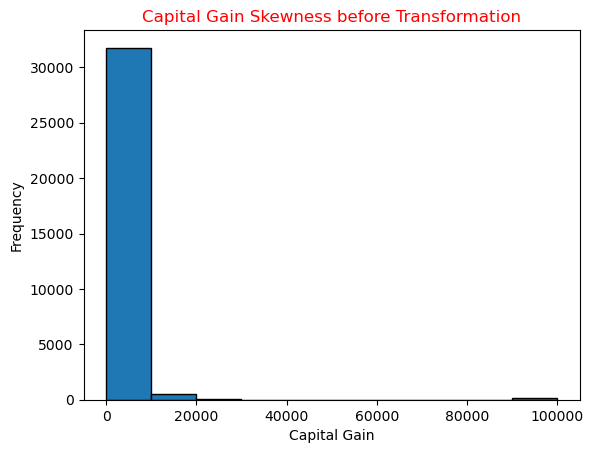

In [42]:
import matplotlib.pyplot as plt
plt.hist(data["capital_gain"],edgecolor="k")
plt.title("Capital Gain Skewness before Transformation",color="red")
plt.xlabel("Capital Gain")
plt.ylabel("Frequency")
plt.show()

### Log Transformation

In [43]:
data["capital_gain_log"]=np.log1p(data["capital_gain"])

In [44]:
data[["capital_gain","capital_gain_log"]].head()

,capital_gain,capital_gain_log
0,2174,7.684784
1,0,0.000000
2,0,0.000000
3,0,0.000000
4,0,0.000000


In [45]:
print("Before Transformation:",
      data["capital_gain"].skew())
print("After Transformation:",
      data["capital_gain_log"].skew())

Before Transformation: 11.949402833551465
After Transformation: 3.094666793136125


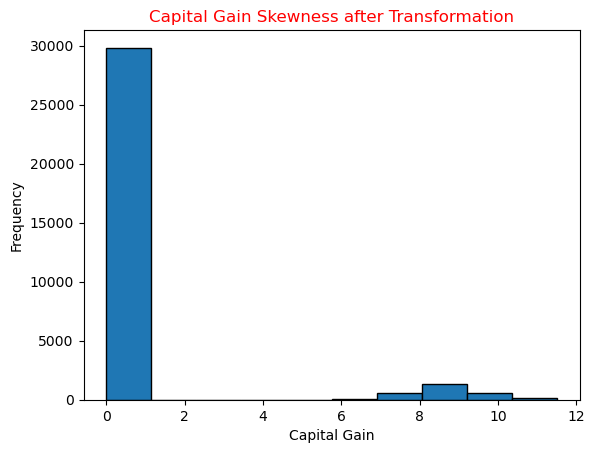

In [46]:
import matplotlib.pyplot as plt
plt.hist(data["capital_gain_log"],edgecolor="k")
plt.title("Capital Gain Skewness after Transformation",color="red")
plt.xlabel("Capital Gain")
plt.ylabel("Frequency")
plt.show()

#### Log Transformation: capital_gain has a highly right-skewed distribution. Log transformation was applied using log1p() to reduce the effect of very large values and make the feature distribution less skewed. log1p() is appropriate because the column contains zero values.

In [47]:
data.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,income,sex_ Female,sex_ Male,net_capital,work_intensity,capital_gain_log
0,39,7,77516,9,13,4,1,1,4,2174,0,40,39,0,0,1,2174,520,7.684784
1,50,6,83311,9,13,2,4,0,4,0,0,13,39,0,0,1,0,169,0.000000
2,38,4,215646,11,9,0,6,1,4,0,0,40,39,0,0,1,0,360,0.000000
3,53,4,234721,1,7,2,6,0,2,0,0,40,39,0,0,1,0,280,0.000000
4,28,4,338409,9,13,2,10,5,2,0,0,40,5,0,1,0,0,520,0.000000


In [48]:
data.shape

(32537, 19)

In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32537 entries, 0 to 32560
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               32537 non-null  int64  
 1   workclass         32537 non-null  int64  
 2   fnlwgt            32537 non-null  int64  
 3   education         32537 non-null  int64  
 4   education_num     32537 non-null  int64  
 5   marital_status    32537 non-null  int64  
 6   occupation        32537 non-null  int64  
 7   relationship      32537 non-null  int64  
 8   race              32537 non-null  int64  
 9   capital_gain      32537 non-null  int64  
 10  capital_loss      32537 non-null  int64  
 11  hours_per_week    32537 non-null  int64  
 12  native_country    32537 non-null  int64  
 13  income            32537 non-null  int64  
 14  sex_ Female       32537 non-null  int64  
 15  sex_ Male         32537 non-null  int64  
 16  net_capital       32537 non-null  int64  
 17

In [50]:
data.isnull().sum()

age                 0
workclass           0
fnlwgt              0
education           0
education_num       0
marital_status      0
occupation          0
relationship        0
race                0
capital_gain        0
capital_loss        0
hours_per_week      0
native_country      0
income              0
sex_ Female         0
sex_ Male           0
net_capital         0
work_intensity      0
capital_gain_log    0
dtype: int64

In [51]:
data.duplicated().sum()

np.int64(0)